In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# Train EDA

In [33]:
train = pd.read_csv("../data/raw/train.csv")

In [34]:
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [35]:
count_stores = train["store_nbr"].nunique()
min_store_count = train["store_nbr"].value_counts().reset_index()["count"].min()
max_store_count = train["store_nbr"].value_counts().reset_index()["count"].max()

print(
    f"count_stores: {count_stores}, min_store_count: {min_store_count}, max_store_count: {max_store_count}"
)

count_family = train["family"].nunique()
min_family_count = train["family"].value_counts().reset_index()["count"].min()
max_family_count = train["family"].value_counts().reset_index()["count"].max()

print(
    f"count_family: {count_family}, min_family_count: {min_family_count}, max_family_count: {max_family_count}"
)

count_stores: 54, min_store_count: 55572, max_store_count: 55572
count_family: 33, min_family_count: 90936, max_family_count: 90936


In [36]:
train["date"] = pd.to_datetime(train["date"])
train["onpromotion"] = train["onpromotion"].astype("category")
train["store_nbr"] = train["store_nbr"].astype("category")
train["family"] = train["family"].astype("category")
train["weekday"] = train["date"].dt.day_of_week
train["month"] = train["date"].dt.month
train["week"] = train["date"].dt.isocalendar().week
train["year"] = train["date"].dt.year

In [37]:
train_agg = train.groupby(["date", "store_nbr", "family"])["sales"].sum().reset_index()

In [38]:
train_agg["sales"].min()

np.float64(0.0)

In [135]:
unique_families = train["family"].unique()
unique_families

['AUTOMOTIVE', 'BABY CARE', 'BEAUTY', 'BEVERAGES', 'BOOKS', ..., 'POULTRY', 'PREPARED FOODS', 'PRODUCE', 'SCHOOL AND OFFICE SUPPLIES', 'SEAFOOD']
Length: 33
Categories (33, str): ['AUTOMOTIVE', 'BABY CARE', 'BEAUTY', 'BEVERAGES', ..., 'PREPARED FOODS', 'PRODUCE', 'SCHOOL AND OFFICE SUPPLIES', 'SEAFOOD']

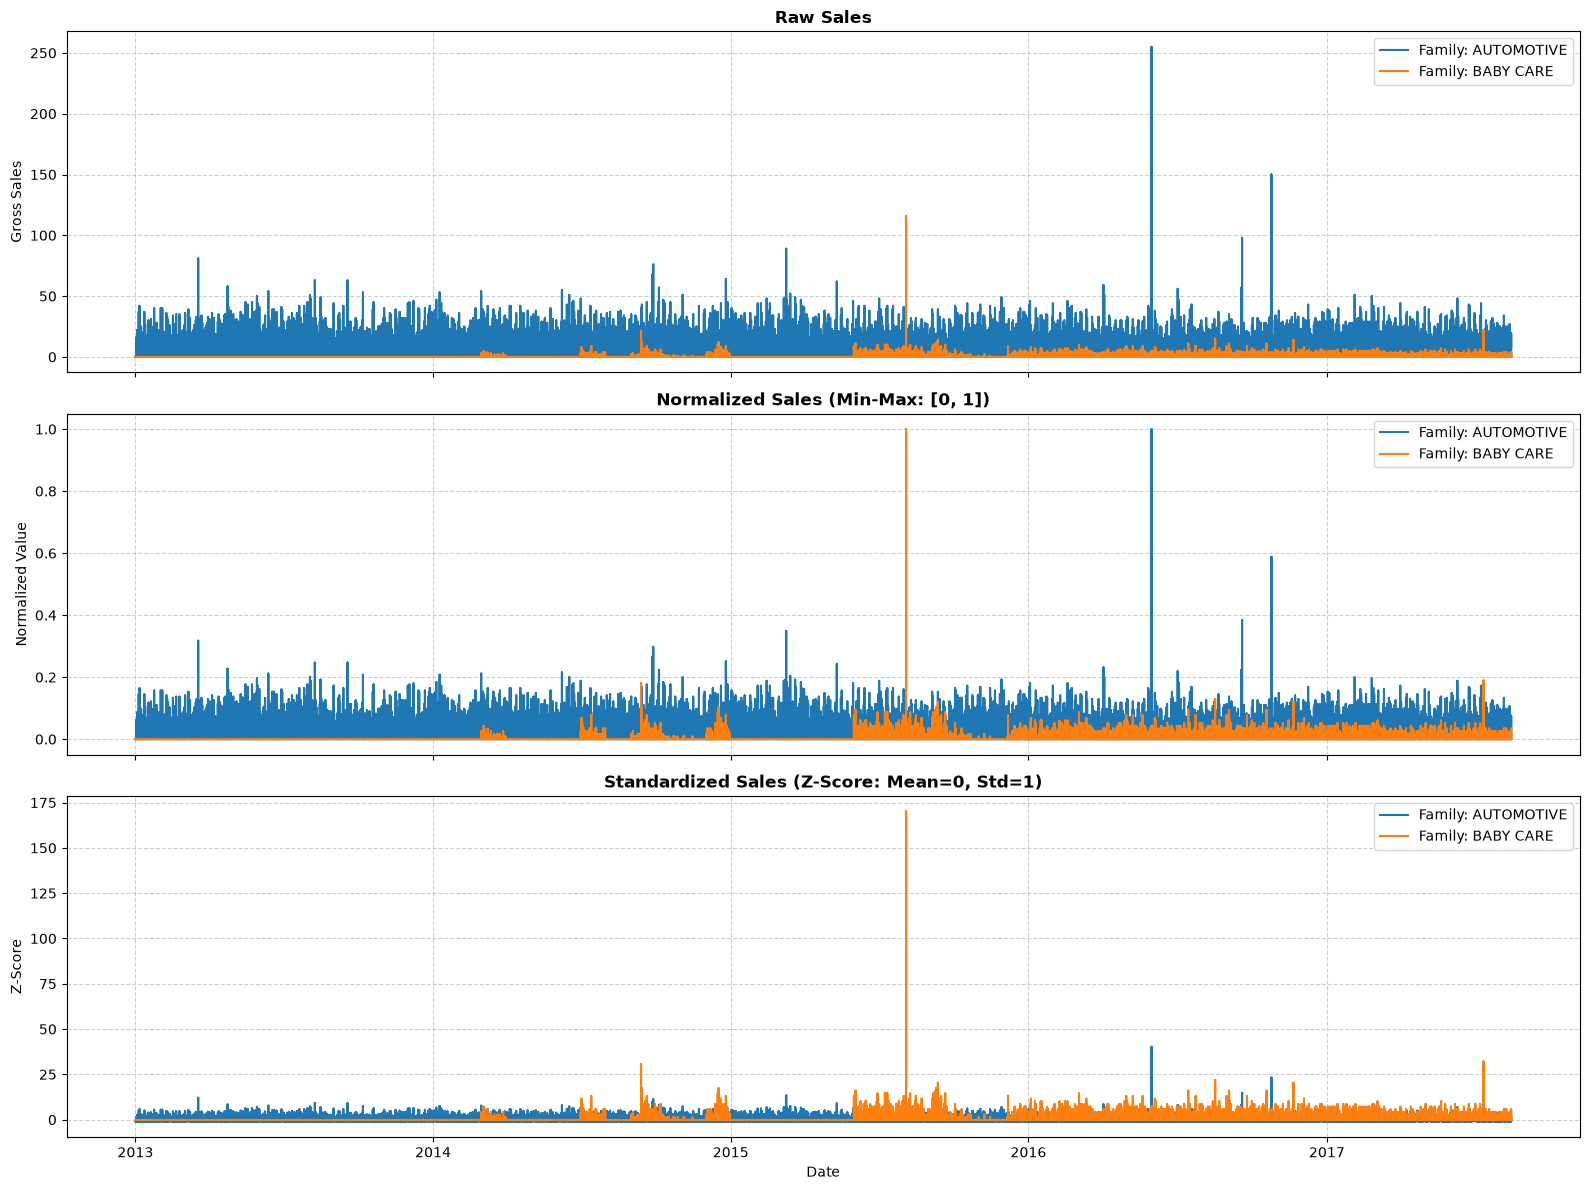

In [41]:
families_selected = ["AUTOMOTIVE", "BABY CARE"]

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

for i in families_selected:
    df_fam = train_agg[train_agg["family"] == i]
    dates = df_fam["date"]
    sales = df_fam["sales"]

    s_min, s_max = sales.min(), sales.max()
    sales_norm = (sales - s_min) / (s_max - s_min) if s_max != s_min else sales * 0

    s_mean, s_std = sales.mean(), sales.std()
    sales_std = (sales - s_mean) / s_std if s_std != 0 else sales * 0

    axes[0].plot(dates, sales, label=f"Family: {i}")
    axes[1].plot(dates, sales_norm, label=f"Family: {i}")
    axes[2].plot(dates, sales_std, label=f"Family: {i}")

axes[0].set_title("Raw Sales", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Gross Sales")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

axes[1].set_title("Normalized Sales (Min-Max: [0, 1])", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Normalized Value")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

axes[2].set_title(
    "Standardized Sales (Z-Score: Mean=0, Std=1)",
    fontsize=12,
    fontweight="bold",
)
axes[2].set_ylabel("Z-Score")
axes[2].set_xlabel("Date")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [42]:
train_agg[(train_agg["sales"] > 100) & (train_agg["family"] == "BABY CARE")]

,date,store_nbr,family,sales
1680889,2015-08-04,15,BABY CARE,116.0


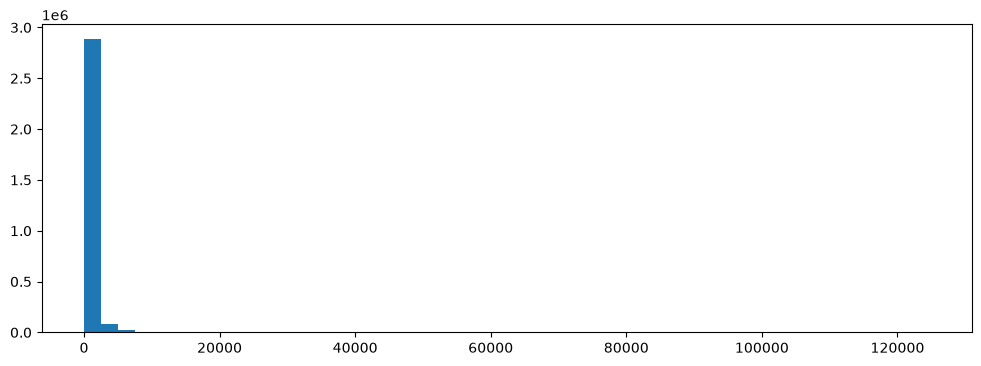

In [43]:
plt.figure(figsize=(12, 4))
plt.hist(train_agg["sales"], bins=50)
plt.show()

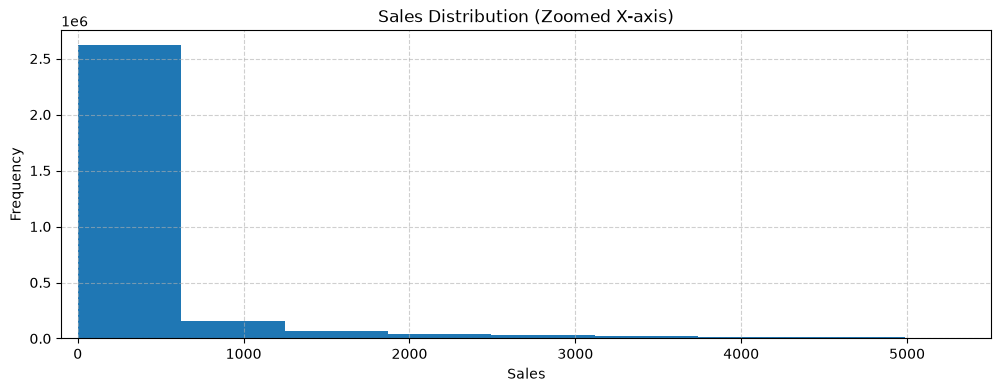

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.hist(train_agg["sales"], bins=200)
plt.xlim(-100, train_agg["sales"].quantile(0.99))
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.title("Sales Distribution (Zoomed X-axis)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

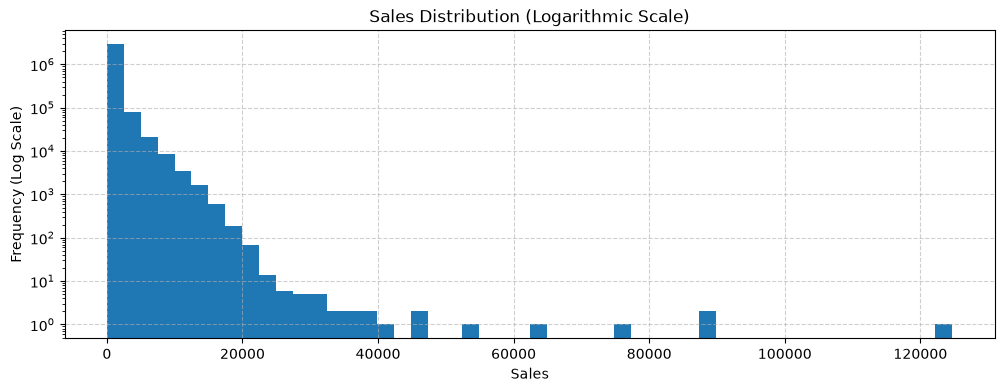

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.hist(train_agg["sales"], bins=50)
plt.yscale("log")
plt.xlabel("Sales")
plt.ylabel("Frequency (Log Scale)")
plt.title("Sales Distribution (Logarithmic Scale)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [46]:
train

,id,date,store_nbr,family,sales,onpromotion,weekday,month,week,year
0,0,2013-01-01,1,AUTOMOTIVE,0.000,0,1,1,1,2013
1,1,2013-01-01,1,BABY CARE,0.000,0,1,1,1,2013
2,2,2013-01-01,1,BEAUTY,0.000,0,1,1,1,2013
3,3,2013-01-01,1,BEVERAGES,0.000,0,1,1,1,2013
4,4,2013-01-01,1,BOOKS,0.000,0,1,1,1,2013
...,...,...,...,...,...,...,...,...,...,...
3000883,3000883,2017-08-15,9,POULTRY,438.133,0,1,8,33,2017
3000884,3000884,2017-08-15,9,PREPARED FOODS,154.553,1,1,8,33,2017
3000885,3000885,2017-08-15,9,PRODUCE,2419.729,148,1,8,33,2017
3000886,3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,8,1,8,33,2017


In [47]:
train.groupby("weekday")["sales"].sum().reset_index()

,weekday,sales
0,0,1.488278e+08
1,1,1.379221e+08
2,2,1.423787e+08
3,3,1.212646e+08
4,4,1.390978e+08
5,5,1.861015e+08
6,6,1.980523e+08


<Figure size 1200x400 with 0 Axes>

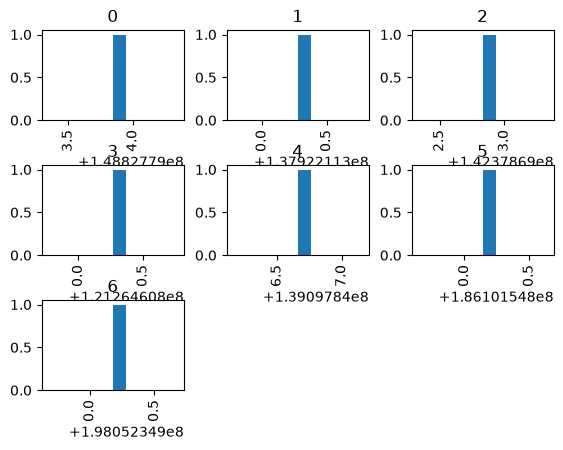

In [110]:
df_to_plot = train.groupby("weekday")["sales"].sum().reset_index()
plt.figure(figsize=(12, 4))
df_to_plot.hist("sales", by="weekday")
plt.show()

In [113]:
train_agg

,date,store_nbr,family,sales
0,2013-01-01,1,AUTOMOTIVE,0.000
1,2013-01-01,1,BABY CARE,0.000
2,2013-01-01,1,BEAUTY,0.000
3,2013-01-01,1,BEVERAGES,0.000
4,2013-01-01,1,BOOKS,0.000
...,...,...,...,...
3000883,2017-08-15,54,POULTRY,59.619
3000884,2017-08-15,54,PREPARED FOODS,94.000
3000885,2017-08-15,54,PRODUCE,915.371
3000886,2017-08-15,54,SCHOOL AND OFFICE SUPPLIES,0.000


In [116]:
train_agg

,date,store_nbr,family,sales
0,2013-01-01,1,AUTOMOTIVE,0.000
1,2013-01-01,1,BABY CARE,0.000
2,2013-01-01,1,BEAUTY,0.000
3,2013-01-01,1,BEVERAGES,0.000
4,2013-01-01,1,BOOKS,0.000
...,...,...,...,...
3000883,2017-08-15,54,POULTRY,59.619
3000884,2017-08-15,54,PREPARED FOODS,94.000
3000885,2017-08-15,54,PRODUCE,915.371
3000886,2017-08-15,54,SCHOOL AND OFFICE SUPPLIES,0.000


In [123]:
df_to_plot

,date,sales
0,2016-10-03,833060.558890
1,2016-10-04,724113.096039
2,2016-10-05,749712.300021
3,2016-10-06,581429.340158
4,2016-10-07,797612.239327


In [126]:
train_agg[(train_agg["date"] >= "2016-02-01") & (train_agg["date"] <= "2016-07-01")]

,date,store_nbr,family,sales
2001186,2016-02-01,1,AUTOMOTIVE,7.000
2001187,2016-02-01,1,BABY CARE,0.000
2001188,2016-02-01,1,BEAUTY,1.000
2001189,2016-02-01,1,BEVERAGES,2450.000
2001190,2016-02-01,1,BOOKS,0.000
...,...,...,...,...
2272045,2016-07-01,54,POULTRY,70.019
2272046,2016-07-01,54,PREPARED FOODS,73.000
2272047,2016-07-01,54,PRODUCE,541.588
2272048,2016-07-01,54,SCHOOL AND OFFICE SUPPLIES,2.000


# Stores EDA

In [49]:
stores = pd.read_csv("../data/raw/stores.csv")
stores["store_nbr"] = stores["store_nbr"].astype("category")
stores["cluster"] = stores["cluster"].astype("category")
stores["type"] = stores["type"].astype("category")

In [50]:
stores.dtypes

store_nbr    category
city              str
state             str
type         category
cluster      category
dtype: object

In [51]:
stores.head()

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [52]:
stores["cluster"].value_counts().reset_index()

,cluster,count
0,3,7
1,6,6
2,10,6
3,15,5
4,13,4
5,14,4
6,1,3
7,4,3
8,8,3
9,11,3


In [53]:
sales_store = train.merge(stores, how="left", on=["store_nbr"])

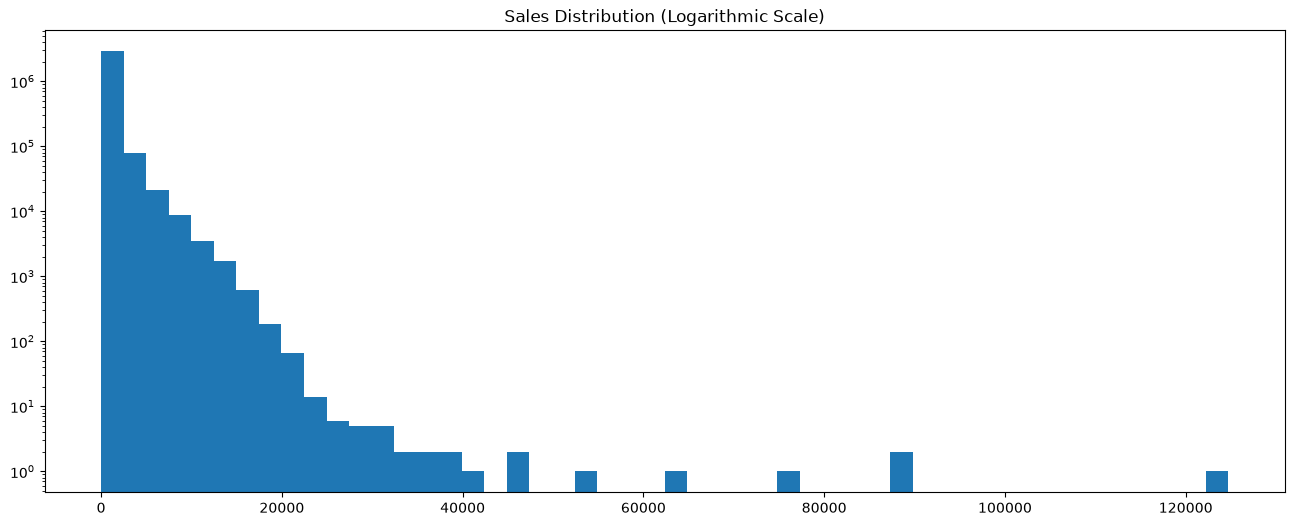

In [54]:
plt.figure(figsize=(16, 6))
plt.hist(sales_store["sales"], bins=50)
plt.yscale("log")
plt.title("Sales Distribution (Logarithmic Scale)")
plt.show()

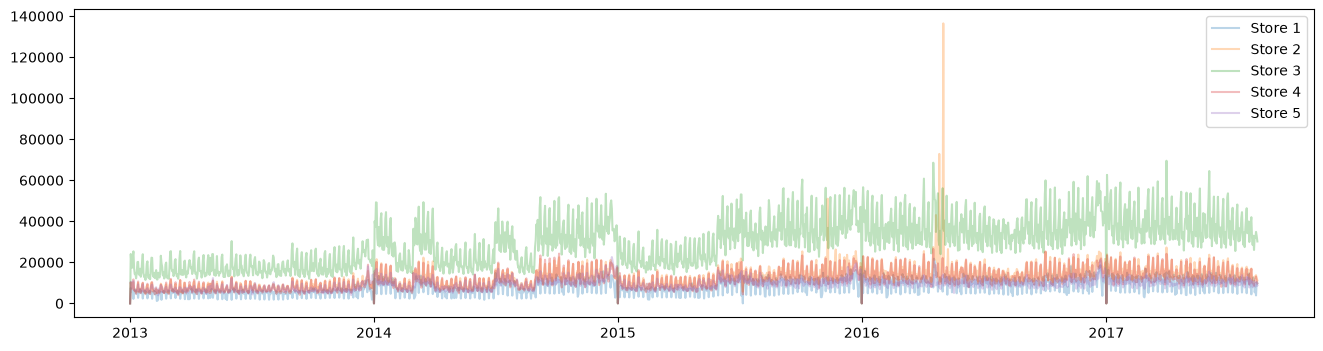

In [55]:
store_list = [1, 2, 3, 4, 5]
plt.figure(figsize=(16, 4))
df_to_plot = (
    sales_store.groupby(["store_nbr", "date", "year"])["sales"].sum().reset_index()
)
for i in store_list:
    to_plot = df_to_plot[df_to_plot["store_nbr"] == i].sort_values("date")
    plt.plot(to_plot["date"], to_plot["sales"], alpha=0.3, label=f"Store {i}")
plt.legend()
plt.show()

    cluster     family  sales
499      16      BOOKS    0.0
70        3      BOOKS    0.0
367      12      BOOKS    0.0
202       7      BOOKS    0.0
430      14  BABY CARE    0.0
331      11  BABY CARE    0.0
169       6      BOOKS    0.0
133       5  BABY CARE    0.0
466      15      BOOKS    0.0
529      17  BABY CARE    0.0


<BarContainer object of 17 artists>

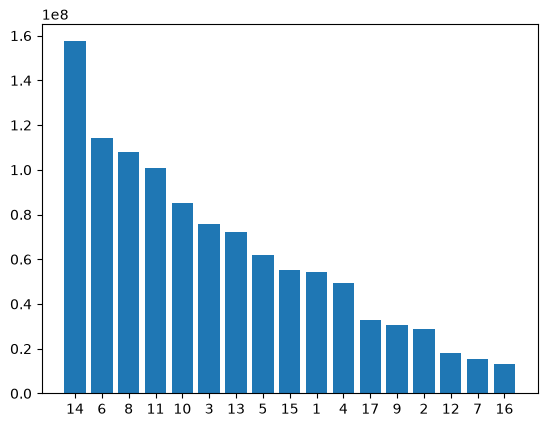

In [56]:
df_to_plot = (
    sales_store.groupby(["cluster", "family"])["sales"]
    .sum()
    .reset_index()
    .sort_values("sales")
)

print(df_to_plot[df_to_plot["sales"] == 0])

df_to_plot = (
    sales_store.groupby(["cluster"])["sales"]
    .sum()
    .reset_index()
    .sort_values("sales", ascending=False)
)

plt.bar(df_to_plot["cluster"].astype(str), df_to_plot["sales"])

    type     family  sales
70     C      BOOKS    0.0
1      A  BABY CARE    0.0
37     B      BOOKS    0.0
136    E      BOOKS    0.0


<BarContainer object of 5 artists>

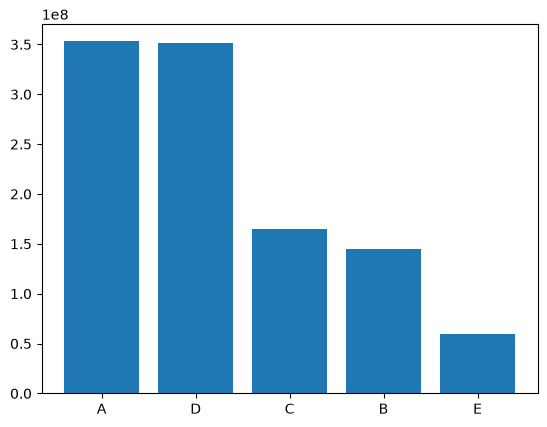

In [57]:
df_to_plot = (
    sales_store.groupby(["type", "family"])["sales"]
    .sum()
    .reset_index()
    .sort_values("sales")
)

print(df_to_plot[df_to_plot["sales"] == 0])

df_to_plot = (
    sales_store.groupby(["type"])["sales"]
    .sum()
    .reset_index()
    .sort_values("sales", ascending=False)
)

plt.bar(df_to_plot["type"].astype(str), df_to_plot["sales"])

In [58]:
top5_sellers = (
    sales_store.groupby("family")["sales"]
    .sum()
    .reset_index()
    .sort_values("sales", ascending=False)
    .iloc[:5]["family"]
)

In [59]:
top5_sellers

12    GROCERY I
3     BEVERAGES
30      PRODUCE
7      CLEANING
8         DAIRY
Name: family, dtype: category
Categories (33, str): ['AUTOMOTIVE', 'BABY CARE', 'BEAUTY', 'BEVERAGES', ..., 'PREPARED FOODS', 'PRODUCE', 'SCHOOL AND OFFICE SUPPLIES', 'SEAFOOD']

In [60]:
df_to_plot = (
    sales_store.loc[lambda df: df.family.isin(top5_sellers)]
    .groupby(["family", "type"])["sales"]
    .sum()
    .reset_index()
)

In [61]:
# square with sales by family

In [62]:
# square with sales by store

In [63]:
# sales map by state

# Holiday events EDA

In [64]:
holidays_events = pd.read_csv("../data/raw/holidays_events.csv")

In [65]:
holidays_events[holidays_events["transferred"] == True]

,date,type,locale,locale_name,description,transferred
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
72,2013-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
135,2014-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
255,2016-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
266,2016-07-25,Holiday,Local,Guayaquil,Fundacion de Guayaquil,True
268,2016-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
297,2017-01-01,Holiday,National,Ecuador,Primer dia del ano,True
303,2017-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,True
312,2017-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
324,2017-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True


In [66]:
holidays_events["type"].value_counts()

type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64

In [67]:
holidays_events[holidays_events["type"] == "Work Day"]

,date,type,locale,locale_name,description,transferred
42,2013-01-05,Work Day,National,Ecuador,Recupero puente Navidad,False
43,2013-01-12,Work Day,National,Ecuador,Recupero puente primer dia del ano,False
149,2014-12-20,Work Day,National,Ecuador,Recupero Puente Navidad,False
161,2015-01-10,Work Day,National,Ecuador,Recupero Puente Primer dia del ano,False
283,2016-11-12,Work Day,National,Ecuador,Recupero Puente Dia de Difuntos,False


In [68]:
true_holidays = holidays_events[holidays_events["transferred"] == False]

In [69]:
true_holidays

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
...,...,...,...,...,...,...
345,2017-12-22,Additional,National,Ecuador,Navidad-3,False
346,2017-12-23,Additional,National,Ecuador,Navidad-2,False
347,2017-12-24,Additional,National,Ecuador,Navidad-1,False
348,2017-12-25,Holiday,National,Ecuador,Navidad,False


In [138]:
stores["city"].value_counts()

city
Quito            18
Guayaquil         8
Santo Domingo     3
Cuenca            3
Latacunga         2
Ambato            2
Machala           2
Manta             2
Cayambe           1
Riobamba          1
Ibarra            1
Guaranda          1
Puyo              1
Salinas           1
Daule             1
Babahoyo          1
Quevedo           1
Playas            1
Libertad          1
Loja              1
Esmeraldas        1
El Carmen         1
Name: count, dtype: int64

In [108]:
true_holidays["locale_name"].value_counts()

locale_name
Ecuador                           166
Riobamba                           12
Guaranda                           12
Latacunga                          12
Ambato                             12
Quito                              12
Guayaquil                          10
Manta                               6
Cotopaxi                            6
Cuenca                              6
Libertad                            6
Puyo                                6
Imbabura                            6
Machala                             6
Santo Domingo                       6
El Carmen                           6
Cayambe                             6
Esmeraldas                          6
Ibarra                              6
Quevedo                             6
Santo Domingo de los Tsachilas      6
Santa Elena                         6
Loja                                6
Salinas                             6
Name: count, dtype: int64

In [156]:
city_holidays

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
5,2012-05-12,Holiday,Local,Puyo,Cantonizacion del Puyo,False
...,...,...,...,...,...,...
338,2017-11-12,Holiday,Local,Ambato,Independencia de Ambato,False
339,2017-12-05,Additional,Local,Quito,Fundacion de Quito-1,False
341,2017-12-08,Holiday,Local,Loja,Fundacion de Loja,False
342,2017-12-08,Transfer,Local,Quito,Traslado Fundacion de Quito,False


In [ ]:
holidays_events = holidays_events[holidays_events["transferred"] == False]

city_holidays = holidays_events[holidays_events["locale"] == "Local"]
national_holidays = holidays_events[holidays_events["locale"] == "National"]
regional_holidays = holidays_events[holidays_events["locale"] == "Regional"]

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
5,2012-05-12,Holiday,Local,Puyo,Cantonizacion del Puyo,False
...,...,...,...,...,...,...
338,2017-11-12,Holiday,Local,Ambato,Independencia de Ambato,False
339,2017-12-05,Additional,Local,Quito,Fundacion de Quito-1,False
341,2017-12-08,Holiday,Local,Loja,Fundacion de Loja,False
342,2017-12-08,Transfer,Local,Quito,Traslado Fundacion de Quito,False


In [152]:
holidays_events = holidays_events[holidays_events["transferred"] == False]

city_holidays = holidays_events[holidays_events["locale"] == "Local"]

national_holidays = holidays_events[holidays_events["locale"] == "National"][
    ["date", "type", "description"]
].copy()
national_holidays["is_holiday"] = 1
store_national = pd.merge(stores[["store_nbr"]], national_holidays, how="cross")

regional_holidays = holidays_events[holidays_events["locale"] == "Regional"]
store_regional = pd.merge(
    stores[["store_nbr", "state"]],
    regional_holidays,
    left_on="state",
    right_on="locale_name",
    how="inner",
)[["store_nbr", "date", "type", "description"]]
store_regional["is_holiday"] = 1

local_holidays = holidays_events[holidays_events["locale"] == "Local"]
store_local = pd.merge(
    stores[["store_nbr", "city"]],
    local_holidays,
    left_on="city",
    right_on="locale_name",
    how="inner",
)[["store_nbr", "date", "type", "description"]]
store_local["is_holiday"] = 1

holidays_per_store = pd.concat(
    [store_national, store_regional, store_local], ignore_index=True
).drop_duplicates(subset=["store_nbr", "date"])

train_merged = pd.merge(
    train,
    holidays_per_store[["store_nbr", "date", "is_holiday"]],
    on=["store_nbr", "date"],
    how="left",
)

train_merged["is_holiday"] = train_merged["is_holiday"].fillna(0)

ValueError: You are trying to merge on datetime64[us] and str columns for key 'date'. If you wish to proceed you should use pd.concat

In [142]:
stores

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4
5,6,Quito,Pichincha,D,13
6,7,Quito,Pichincha,D,8
7,8,Quito,Pichincha,D,8
8,9,Quito,Pichincha,B,6
9,10,Quito,Pichincha,C,15


Transform holidays into something
Add paiments on 15th and last day of the month
Add earthquake on april 16 2016 and followin days; check where was it

Create 3 columns
- national holiday
- local holiday (related to location)
- add paiments 

#clean data after earthquake

In [136]:
unique_families

['AUTOMOTIVE', 'BABY CARE', 'BEAUTY', 'BEVERAGES', 'BOOKS', ..., 'POULTRY', 'PREPARED FOODS', 'PRODUCE', 'SCHOOL AND OFFICE SUPPLIES', 'SEAFOOD']
Length: 33
Categories (33, str): ['AUTOMOTIVE', 'BABY CARE', 'BEAUTY', 'BEVERAGES', ..., 'PREPARED FOODS', 'PRODUCE', 'SCHOOL AND OFFICE SUPPLIES', 'SEAFOOD']

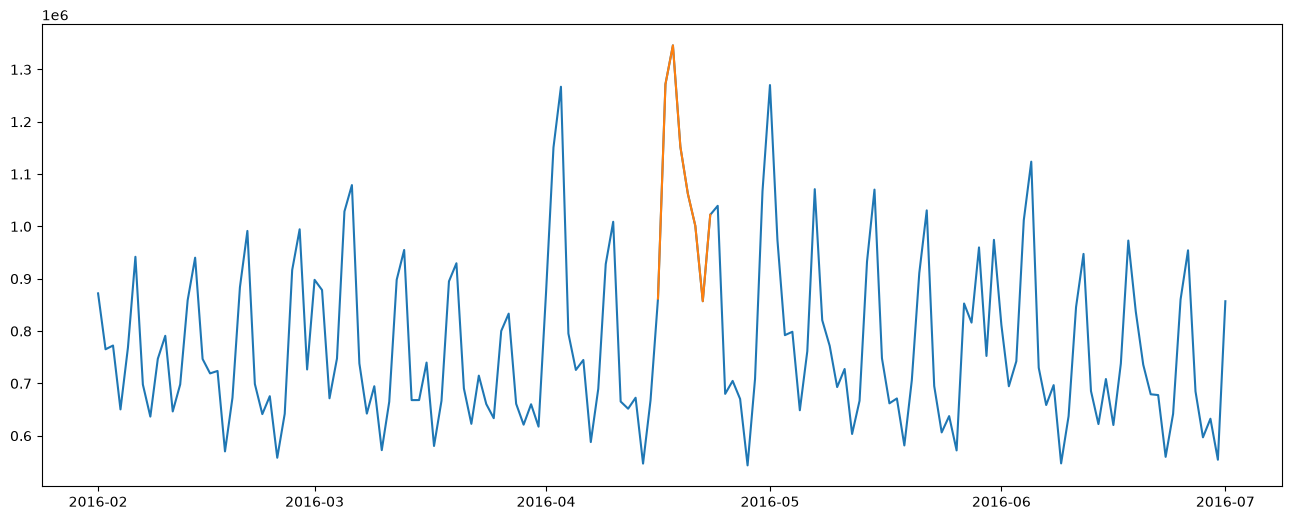

In [ ]:
families_eq = []
state_eq = []
df_to_plot = (
    sales_store[
        (sales_store["date"] >= "2016-02-01")
        & (sales_store["date"] <= "2016-07-01")
        & (sales_store["family"].isin(families_eq))
        & (sales_store["state"].isin(state_eq))
    ]
    .groupby(["date"])["sales"]
    .sum()
    .reset_index()
)
df_to_plot_hq = df_to_plot[
    (df_to_plot["date"] >= "2016-04-16") & (df_to_plot["date"] <= "2016-04-23")
]


plt.figure(figsize=(16, 6))
plt.plot(df_to_plot["date"], df_to_plot["sales"])
plt.plot(df_to_plot_hq["date"], df_to_plot_hq["sales"])
plt.show()

In [143]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Ensure date type and filter a window around the earthquake (e.g., 30 days before and after)
train["date"] = pd.to_datetime(train["date"])
earthquake_date = pd.to_datetime("2016-04-16")

window_start = earthquake_date - pd.Timedelta(days=30)
window_end = earthquake_date + pd.Timedelta(days=30)

df_quake = train[(train["date"] >= window_start) & (train["date"] <= window_end)].copy()

# 2. Create a flag for Post-Earthquake period
df_quake["period"] = np.where(df_quake["date"] >= earthquake_date, "Post", "Pre")

# 3. Analyze impact by Store (comparing average sales before vs after)
store_impact = df_quake.groupby(["store_nbr", "period"])["sales"].mean().unstack()
store_impact["pct_change"] = (
    (store_impact["Post"] - store_impact["Pre"]) / store_impact["Pre"]
) * 100
store_impact = store_impact.sort_values(by="pct_change", ascending=False)

print("Top stores positively impacted (e.g., relief supplies):")
print(store_impact.head(5))

print("\nTop stores negatively impacted:")
print(store_impact.tail(5))

# 4. Analyze impact by Product Family
family_impact = df_quake.groupby(["family", "period"])["sales"].mean().unstack()
family_impact["pct_change"] = (
    (family_impact["Post"] - family_impact["Pre"]) / family_impact["Pre"]
) * 100
family_impact = family_impact.sort_values(by="pct_change", ascending=False)

print("\nFamilies with highest surge (e.g., water, paper products, canned food):")
print(family_impact.head(5))

print("\nFamilies with highest drop (e.g., luxury, non-essentials):")
print(family_impact.tail(5))

Top stores positively impacted (e.g., relief supplies):
period           Post         Pre  pct_change
store_nbr                                    
53         492.196835  236.590042  108.037849
2          739.021932  456.908142   61.744093
20         626.234087  412.380261   51.858405
29         429.154962  303.895266   41.218048
18         424.030807  305.713258   38.702132

Top stores negatively impacted:
period           Post         Pre  pct_change
store_nbr                                    
5          303.303722  291.178973    4.164020
37         411.956407  396.783981    3.823850
35         173.295204  171.288521    1.171522
25         196.121477  322.519115  -39.190743
52           0.000000    0.000000         NaN

Families with highest surge (e.g., water, paper products, canned food):
period                          Post       Pre  pct_change
family                                                    
SCHOOL AND OFFICE SUPPLIES  8.764636  2.403086  264.724112
HOME APPLIANCES  

# OIL EDA

In [71]:
oil = pd.read_csv("../data/raw/oil.csv")

In [72]:
oil

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20
...,...,...
1213,2017-08-25,47.65
1214,2017-08-28,46.40
1215,2017-08-29,46.46
1216,2017-08-30,45.96


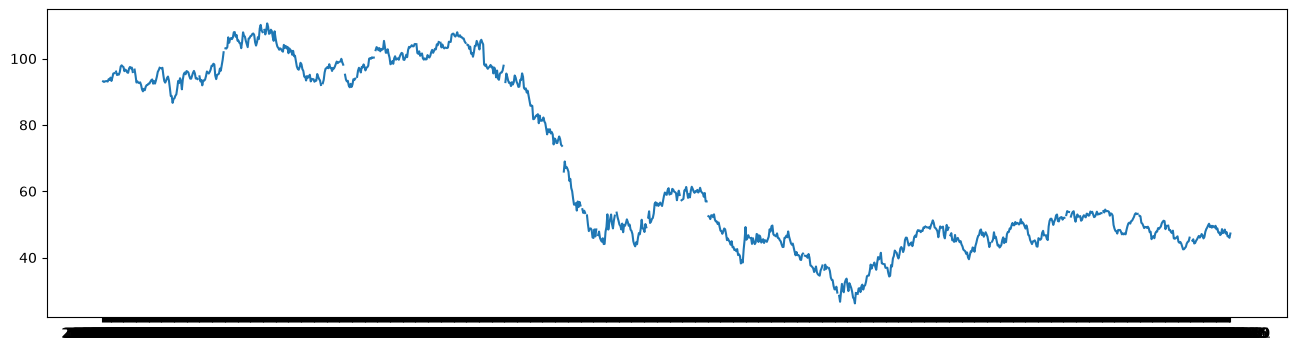

In [73]:
plt.figure(figsize=(16, 4))
plt.plot(oil["date"], oil["dcoilwtico"])
plt.show()

In [ ]:
# interpolate blank spaces

# The oil dataset is empty for some holidays. Interpolate empty spaces with the mean of previous and following day
oil[oil["dcoilwtico"].isna()]

,date,dcoilwtico,dcoilwtico_last_4weeks
0,2013-01-01,NaN,NaN
14,2013-01-21,NaN,NaN
34,2013-02-18,NaN,NaN
63,2013-03-29,NaN,NaN
104,2013-05-27,NaN,NaN
132,2013-07-04,NaN,NaN
174,2013-09-02,NaN,NaN
237,2013-11-28,NaN,NaN
256,2013-12-25,NaN,NaN
261,2014-01-01,NaN,NaN


In [100]:
# feature engineering, mean price 1 month before?

oil["dcoilwtico_last_4weeks"] = oil.rolling(window=28)["dcoilwtico"].mean()
oil

,date,dcoilwtico,dcoilwtico_last_4weeks
0,2013-01-01,NaN,NaN
1,2013-01-02,93.14,NaN
2,2013-01-03,92.97,NaN
3,2013-01-04,93.12,NaN
4,2013-01-07,93.20,NaN
...,...,...,...
1213,2017-08-25,47.65,48.211429
1214,2017-08-28,46.40,48.186429
1215,2017-08-29,46.46,48.176786
1216,2017-08-30,45.96,48.183214


# Transactions EDA

In [150]:
transactions = pd.read_csv("../data/raw/transactions.csv")
transactions["date"] = pd.to_datetime(transactions["date"])

In [151]:
transactions[transactions["transactions"].isnull()]

,date,store_nbr,transactions


In [79]:
sales_store_t = sales_store.merge(transactions, how="left", on=["store_nbr", "date"])

In [84]:
sales_store_t[sales_store_t["transactions"].notna()]

,id,date,store_nbr,family,sales,onpromotion,weekday,month,week,year,city,state,type,cluster,transactions
561,561,2013-01-01,25,AUTOMOTIVE,0.000,0,1,1,1,2013,Salinas,Santa Elena,D,1,770.0
562,562,2013-01-01,25,BABY CARE,0.000,0,1,1,1,2013,Salinas,Santa Elena,D,1,770.0
563,563,2013-01-01,25,BEAUTY,2.000,0,1,1,1,2013,Salinas,Santa Elena,D,1,770.0
564,564,2013-01-01,25,BEVERAGES,810.000,0,1,1,1,2013,Salinas,Santa Elena,D,1,770.0
565,565,2013-01-01,25,BOOKS,0.000,0,1,1,1,2013,Salinas,Santa Elena,D,1,770.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3000883,3000883,2017-08-15,9,POULTRY,438.133,0,1,8,33,2017,Quito,Pichincha,B,6,2155.0
3000884,3000884,2017-08-15,9,PREPARED FOODS,154.553,1,1,8,33,2017,Quito,Pichincha,B,6,2155.0
3000885,3000885,2017-08-15,9,PRODUCE,2419.729,148,1,8,33,2017,Quito,Pichincha,B,6,2155.0
3000886,3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,8,1,8,33,2017,Quito,Pichincha,B,6,2155.0


In [86]:
sales_store_t[sales_store_t["date"] == "2013-01-02"]

,id,date,store_nbr,family,sales,onpromotion,weekday,month,week,year,city,state,type,cluster,transactions
1782,1782,2013-01-02,1,AUTOMOTIVE,2.000,0,2,1,1,2013,Quito,Pichincha,D,13,2111.0
1783,1783,2013-01-02,1,BABY CARE,0.000,0,2,1,1,2013,Quito,Pichincha,D,13,2111.0
1784,1784,2013-01-02,1,BEAUTY,2.000,0,2,1,1,2013,Quito,Pichincha,D,13,2111.0
1785,1785,2013-01-02,1,BEVERAGES,1091.000,0,2,1,1,2013,Quito,Pichincha,D,13,2111.0
1786,1786,2013-01-02,1,BOOKS,0.000,0,2,1,1,2013,Quito,Pichincha,D,13,2111.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3559,3559,2013-01-02,9,POULTRY,651.292,0,2,1,1,2013,Quito,Pichincha,B,6,2940.0
3560,3560,2013-01-02,9,PREPARED FOODS,83.000,0,2,1,1,2013,Quito,Pichincha,B,6,2940.0
3561,3561,2013-01-02,9,PRODUCE,0.000,0,2,1,1,2013,Quito,Pichincha,B,6,2940.0
3562,3562,2013-01-02,9,SCHOOL AND OFFICE SUPPLIES,0.000,0,2,1,1,2013,Quito,Pichincha,B,6,2940.0


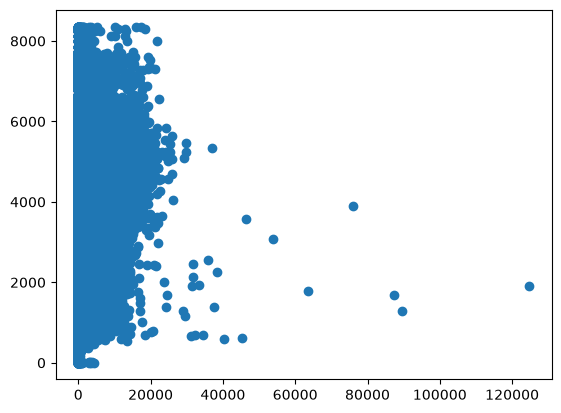

In [88]:
sales_store_t[sales_store_t["date"] == "2013-01-03"]
plt.scatter(sales_store_t["sales"], sales_store_t["transactions"])

In [93]:
sales_store_t[sales_store_t["transactions"] == 0]

,id,date,store_nbr,family,sales,onpromotion,weekday,month,week,year,city,state,type,cluster,transactions
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,1,1,1,2013,Quito,Pichincha,D,13,0.0
1,1,2013-01-01,1,BABY CARE,0.0,0,1,1,1,2013,Quito,Pichincha,D,13,0.0
2,2,2013-01-01,1,BEAUTY,0.0,0,1,1,1,2013,Quito,Pichincha,D,13,0.0
3,3,2013-01-01,1,BEVERAGES,0.0,0,1,1,1,2013,Quito,Pichincha,D,13,0.0
4,4,2013-01-01,1,BOOKS,0.0,0,1,1,1,2013,Quito,Pichincha,D,13,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2790409,2790409,2017-04-19,52,POULTRY,0.0,0,2,4,16,2017,Manta,Manabi,A,11,0.0
2790410,2790410,2017-04-19,52,PREPARED FOODS,0.0,0,2,4,16,2017,Manta,Manabi,A,11,0.0
2790411,2790411,2017-04-19,52,PRODUCE,0.0,0,2,4,16,2017,Manta,Manabi,A,11,0.0
2790412,2790412,2017-04-19,52,SCHOOL AND OFFICE SUPPLIES,0.0,0,2,4,16,2017,Manta,Manabi,A,11,0.0


In [92]:
import numpy as np

sales_store_t["transactions"] = np.where(
    sales_store_t["transactions"].isna(), 0, sales_store_t["transactions"]
)

# Data Transformation

- Function for each dataset's transformation
- Function for merge all datasets
- 

